# Development Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for evaluating the explicitly selected Meta and Primary configurations; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `sentiment_asynchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `development` — Use the fixed development evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-07-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `horizon_bars=1560`, `horizontal_multipliers=[5.0, 5.0]`, `max_positions_per_side=10`, `step_size=0.10`, `half_life_minutes=780.0`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set holding horizon, the total position limit per direction in the single book, sizing, initial capital, and trading costs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "sentiment_asynchronous"
PARTITION = "development"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-07-01", tz="UTC")

settings = PortfolioSettings(
    horizon_bars=1560,
    horizontal_multipliers=[5.0, 5.0],
    max_positions_per_side=10, step_size=0.10, half_life_minutes=780.0,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="sentiment", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Strategy Validation

- **Purpose:** Refit the explicitly selected Primary and Meta configurations within each split; this development-tuned evaluation is not an unbiased model-selection estimate.
- **Input:** Development events and frozen primary/meta configurations only.
- **Output:** In-memory test-only CPCV predictions, 15 split definitions, and five complete paths for the selected model, with displayed split definitions.
- **outer_num_total_groups:** `6` — Divide development into contiguous CPCV groups.
- **outer_num_test_groups:** `2` — Hold out two groups per combination, producing 15 splits and five paths.
- **outer_pct_embargo:** `0.01` — Apply outer-fold embargo alongside purging.
- **inner_num_splits:** `5` — Generate primary OOF inputs for meta training within each outer training set.
- **inner_pct_embargo:** `0.01` — Apply embargo to inner primary OOF folds.

In [3]:
validation_settings = dict(
    outer_num_total_groups=6, outer_num_test_groups=2, outer_pct_embargo=0.01,
    inner_num_splits=5, inner_pct_embargo=0.01,
)
predictions, splits = development_predictions(inputs, **validation_settings)
display(splits.set_index("split_num")[["train_groups", "test_groups"]])

,train_groups,test_groups
split_num,,
0,"(2, 3, 4, 5)","(0, 1)"
1,"(1, 3, 4, 5)","(0, 2)"
2,"(1, 2, 4, 5)","(0, 3)"
3,"(1, 2, 3, 5)","(0, 4)"
4,"(1, 2, 3, 4)","(0, 5)"
5,"(0, 3, 4, 5)","(1, 2)"
6,"(0, 2, 4, 5)","(1, 3)"
7,"(0, 2, 3, 5)","(1, 4)"
8,"(0, 2, 3, 4)","(1, 5)"


## Bet Sizing

- **Purpose:** Prepare signed signals with split-training-only price calibration for asynchronous selection and sizing.
- **Input:** CPCV path predictions and split-training calibration data.
- **Output:** In-memory events and aligned calibration tables.


In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared completed dollar-bar stream.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions; progress counts processed bars.
- **Execution:** Apply asynchronous signal updates, event-driven selection, capped directional allocation, later own-symbol bar fills, and final-bar liquidation.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing dollar bars


Finalizing accounts: 100%|##########| 36890153/36890153 [04:26<00:00, 138519.58bar/s, accounts=5; 2025-10-23 19:59:59.698265+00:00]


## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** One selected-model statistics table and one cumulative-return graph; save `statistics.parquet` and `settings.json` under `data/backtesting/sentiment_asynchronous/development`. Account curves, detailed trades, and intermediate predictions remain in memory; see the [storage decision](../../../docs/decisions.md#12-database).
- **Display:** For the explicitly selected model family, show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; Primary reports precision/recall/F1 for both -1 and +1, Meta for class 1, and both report accuracy, positive log loss, PR-AUC, and ROC-AUC using the shared modeling calculations; no classification graphs are added; recompute statistics before rerunning display to obtain the new metrics; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Model-family headings are omitted; graph titles show only strategy and partition. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03T14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23T20:00:00+00:00   
                         average_aum                     USD                       105271.74367497707   
                         leverage                        ratio                     0.6541769698554672   
                         maximum_dollar_position_size    USD                       111810.94696048979   
                         ratio_of_longs                  ratio                     0.5472602739726027   
                         frequency_of_bets               count/year                2033.5838572030011   
                         average_holding_period          days                      1.5328427705317098   
                         annualized_turnover             ratio                      366.5809162859422   
                         correlation_to_underlying       ratio                   -0.24210002917171997   
performance              pnl                             USD                        7936.441168381847   
                         annualized_rate_of_return       ratio                    0.11224048680335108   
                         pnl_from_long_positions         USD                        5579.099667784692   
                         pnl_from_short_positions        USD                        2357.341500596452   
                         hit_ratio                       ratio                    0.46164383561643835   
                         average_return_from_hits        ratio                  0.0017933327888057153   
                         average_return_from_misses      ratio                 -0.0014340266584996692   
runs                     hhi_positive_returns            ratio                   0.001506051242766561   
                         hhi_negative_returns            ratio                   0.001004075212250796   
                         hhi_time_between_bets           ratio                   0.006311925314317892   
                         percentile_drawdown             ratio                   0.015586671498923562   
                         percentile_time_under_water     years                   0.010530207002915253   
implementation_shortfall broker_fees_per_turnover        ratio                  9.999999513546942e-05   
                         average_slippage_per_turnover   ratio                  0.0001000000000000001   
                         dollar_performance_per_turnover ratio                 0.00028645299167885717   
                         return_on_execution_costs       ratio                     1.4322649932307694   
efficiency               sharpe_ratio                    ratio                   0.036951886749110874   
                         annualized_sharpe_ratio         ratio                     0.7062065324747832   
                         probabilistic_sharpe_ratio      ratio                     0.4018021158964603   
classification_scores    primary_accuracy                score                     0.5949522433050517   
                         primary_precision_-1            score                     0.5995943271645657   
                         primary_recall_-1               score                       0.51123082965796   
                         primary_f1_-1                   score                     0.5518980254486999   
                         primary_precision_1             score                     0.5916454573136969   
                         primary_recall_1                score                     0.6747210019865691   
                         primary_f1_1                    score                     0.6304582893013071   
                         primary_log_loss                score                     0.6642088046748795   


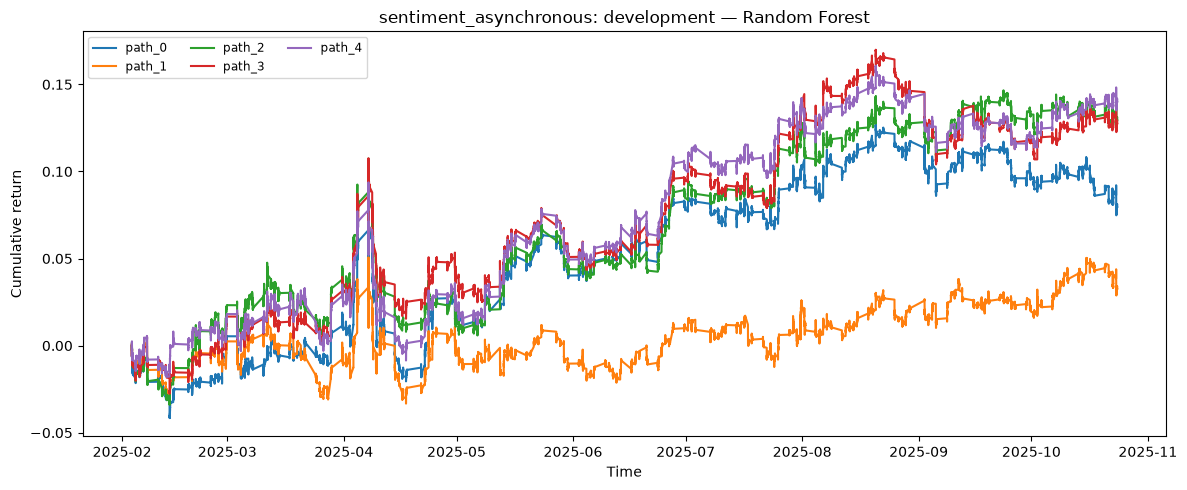

In [7]:
for family in statistics["model_family"].drop_duplicates():
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/sentiment_asynchronous/development
